# Prioritize marker and candidate genes

Inspect genes associated with B-lineage programs in Pan-GI, then
visualize their expression in the model embedding. This example
accompanies Figure 5e and Supplementary Figure 4a.

## 1. Load the gene associations

`Known` denotes a match to the population's CellMarker or PanglaoDB marker set in the archived analysis. `Candidate` denotes an association outside those sets, not a newly validated marker.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import (configure_plots, save_figure, clean_map, pretty,
                     expression_cmap, program_cmap, pathway_cmap, dot_atlas)

configure_plots()
DATA = ROOT / "tutorials/data"
OUTPUT = ROOT / "tutorials/outputs"

In [2]:
cells = pd.read_csv(DATA / "pangi_cells.csv.gz", dtype={"cell_id": str})
rankings = pd.read_csv(DATA / "pangi_gene_rankings.csv")
display(rankings.groupby("cell_type", sort=False).head(5).round(3))

,cell_type,feature_id,rank,gene,correlation,marker_status
0,Mature_B,88,1,MS4A1,0.728,Known
1,Mature_B,88,2,CD79A,0.661,Known
2,Mature_B,88,3,VPREB3,0.641,Candidate
3,Mature_B,88,4,CD52,0.545,Candidate
4,Mature_B,88,5,BANK1,0.537,Known
60,B_plasma,1551,1,TNFRSF17,0.702,Known
61,B_plasma,1551,2,MZB1,0.680,Known
62,B_plasma,1551,3,DERL3,0.663,Known
63,B_plasma,1551,4,FCRL5,0.496,Known
64,B_plasma,1551,5,JSRP1,0.479,Known


## 2. Visualize program-gene associations

The archived association scores use rectified pre-Top-K guided
activations and log1p-transformed prepared expression values. Edge
width shows association strength, and node color distinguishes known
markers from candidates. These are program-gene associations, not a
gene-regulatory network.

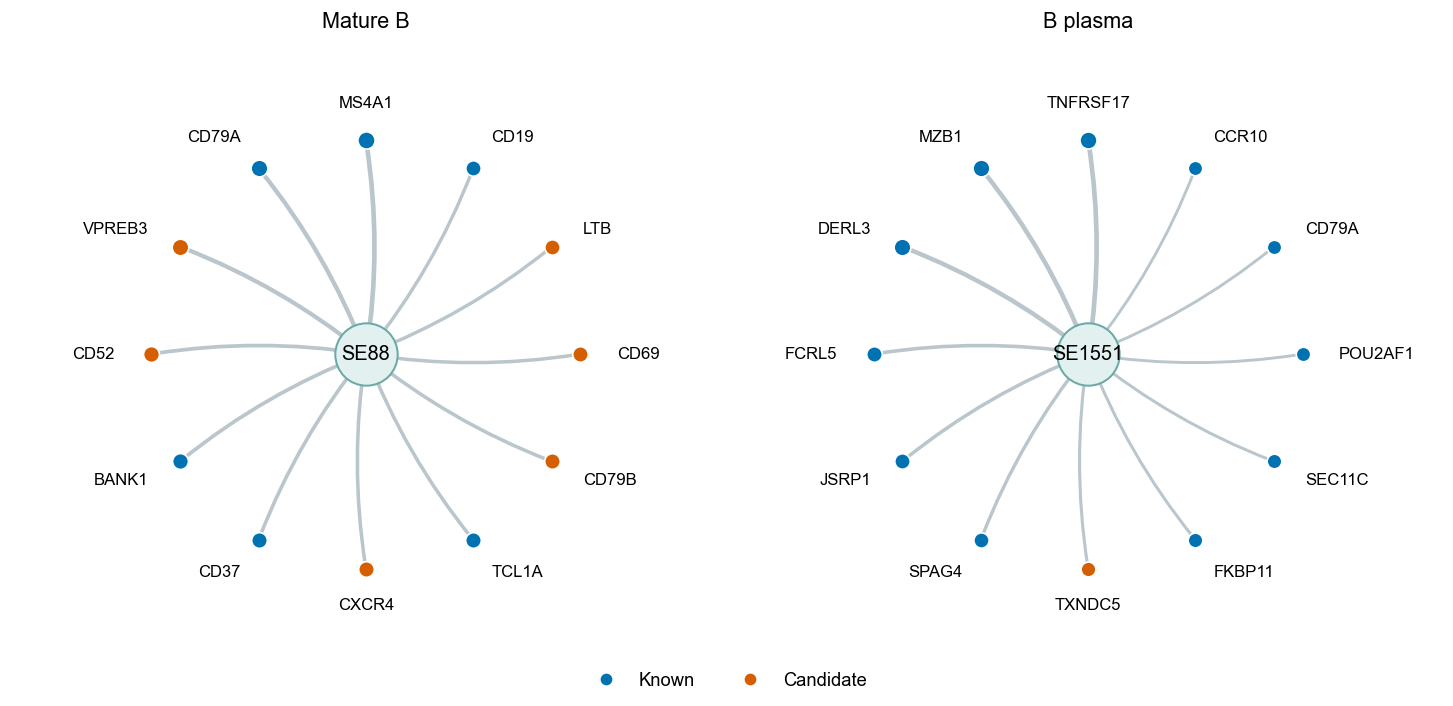

In [3]:
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

status_colors = {"Known": "#0072B2", "Candidate": "#D55E00"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout="constrained")
for ax, population in zip(axes, ["Mature_B", "B_plasma"]):
    top = rankings.loc[rankings.cell_type.eq(population)].sort_values("rank").head(12)
    angles = np.linspace(np.pi/2, np.pi/2 + 2*np.pi, len(top), endpoint=False)
    for angle, item in zip(angles, top.itertuples()):
        x, y = np.cos(angle), np.sin(angle)
        edge = FancyArrowPatch((0, 0), (x, y), arrowstyle="-",
                              connectionstyle="arc3,rad=0.08", color="#bac6cc",
                              linewidth=0.6 + 2.2 * item.correlation/top.correlation.max())
        ax.add_patch(edge)
        ax.scatter(x, y, s=45 + 85*item.correlation, color=status_colors[item.marker_status],
                   edgecolor="white", linewidth=1, zorder=3)
        ax.text(1.17*x, 1.17*y, item.gene, fontsize=10,
                ha="center" if abs(x)<0.1 else ("left" if x>0 else "right"), va="center")
    ax.scatter(0, 0, s=1400, c="#e2f1ef", edgecolor="#69a9a7", linewidth=1.2, zorder=4)
    ax.text(0, 0, f"SE{int(top.feature_id.iloc[0])}", ha="center", va="center", fontsize=12, zorder=5)
    ax.set_title(pretty(population), pad=16)
    ax.set_xlim(-1.65, 1.65)
    ax.set_ylim(-1.4, 1.4)
    clean_map(ax)
fig.legend(handles=[Line2D([], [], marker="o", linestyle="", color=c, label=s)
                    for s,c in status_colors.items()], loc="outside lower center", ncol=2)
save_figure(fig, OUTPUT, "pangi_program_gene_networks")
plt.show()

## 3. Recompute selected correlations

Pearson correlations from the bundled cell-level data closely reproduce the archived scores; small differences arise from epsilon stabilization in the original matrix calculation.

In [4]:
pairs = [(88, "MS4A1"), (88, "VPREB3"), (1551, "TNFRSF17"), (1551, "TXNDC5")]
rows = []
for feature, gene in pairs:
    observed = cells[f"guided_SE{feature}"].corr(cells[gene])
    archived = rankings.loc[(rankings.feature_id == feature) & rankings.gene.eq(gene), "correlation"].iloc[0]
    rows.append({"Program": f"SE{feature}", "Gene": gene,
                 "Pearson r": observed, "Archived score": archived})
correlations = pd.DataFrame(rows)
assert np.allclose(correlations["Pearson r"], correlations["Archived score"], atol=2e-4)
display(correlations.round(3))

,Program,Gene,Pearson r,Archived score
0,SE88,MS4A1,0.728,0.728
1,SE88,VPREB3,0.641,0.641
2,SE1551,TNFRSF17,0.702,0.702
3,SE1551,TXNDC5,0.399,0.399


## 4. Localize known and candidate genes

All panels use the same UMAP coordinates. Zero-expression cells remain visible in light gray; color scales are gene-specific.

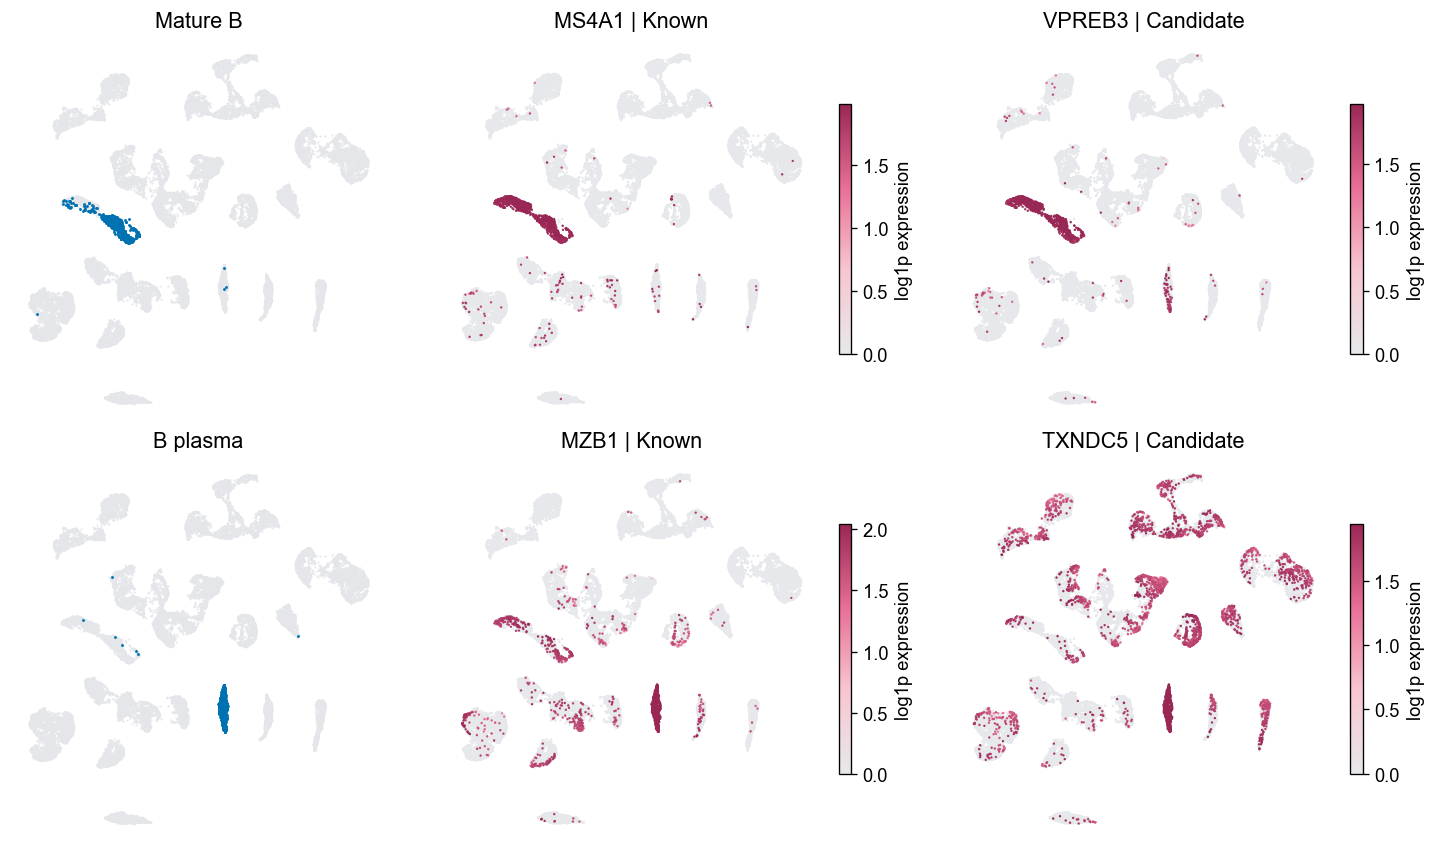

In [5]:
panels = [("Mature_B", "MS4A1", "VPREB3"), ("B_plasma", "MZB1", "TXNDC5")]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for row, (population, known, candidate) in enumerate(panels):
    ax = axes[row, 0]
    ax.scatter(cells.UMAP1, cells.UMAP2, s=1.5, c="#e4e6e9", linewidths=0)
    subset = cells.loc[cells.cell_type.eq(population)]
    ax.scatter(subset.UMAP1, subset.UMAP2, s=3, c="#0072B2", linewidths=0)
    ax.set_title(pretty(population))
    clean_map(ax)
    for col, gene, status in [(1, known, "Known"), (2, candidate, "Candidate")]:
        ax = axes[row, col]
        ordered = cells.sort_values(gene)
        vmax = max(float(cells[gene].quantile(0.99)), 1e-6)
        image = ax.scatter(ordered.UMAP1, ordered.UMAP2, c=ordered[gene],
                           s=2, cmap=expression_cmap(), vmin=0, vmax=vmax, linewidths=0)
        ax.set_title(f"{gene} | {status}")
        clean_map(ax)
        fig.colorbar(image, ax=ax, shrink=0.65, label="log1p expression")
save_figure(fig, OUTPUT, "pangi_marker_expression_umap")
plt.show()

VPREB3 and TXNDC5 show expression in the corresponding B-lineage compartments. Expression localization supports these associations but does not establish exclusive subtype specificity or functional relevance.

## 5. Compare expression across populations

Dot area reports the fraction of cells expressing a gene. Color shows
mean expression scaled to each gene's maximum across all populations.
Broader candidate expression remains visible alongside B-lineage markers.

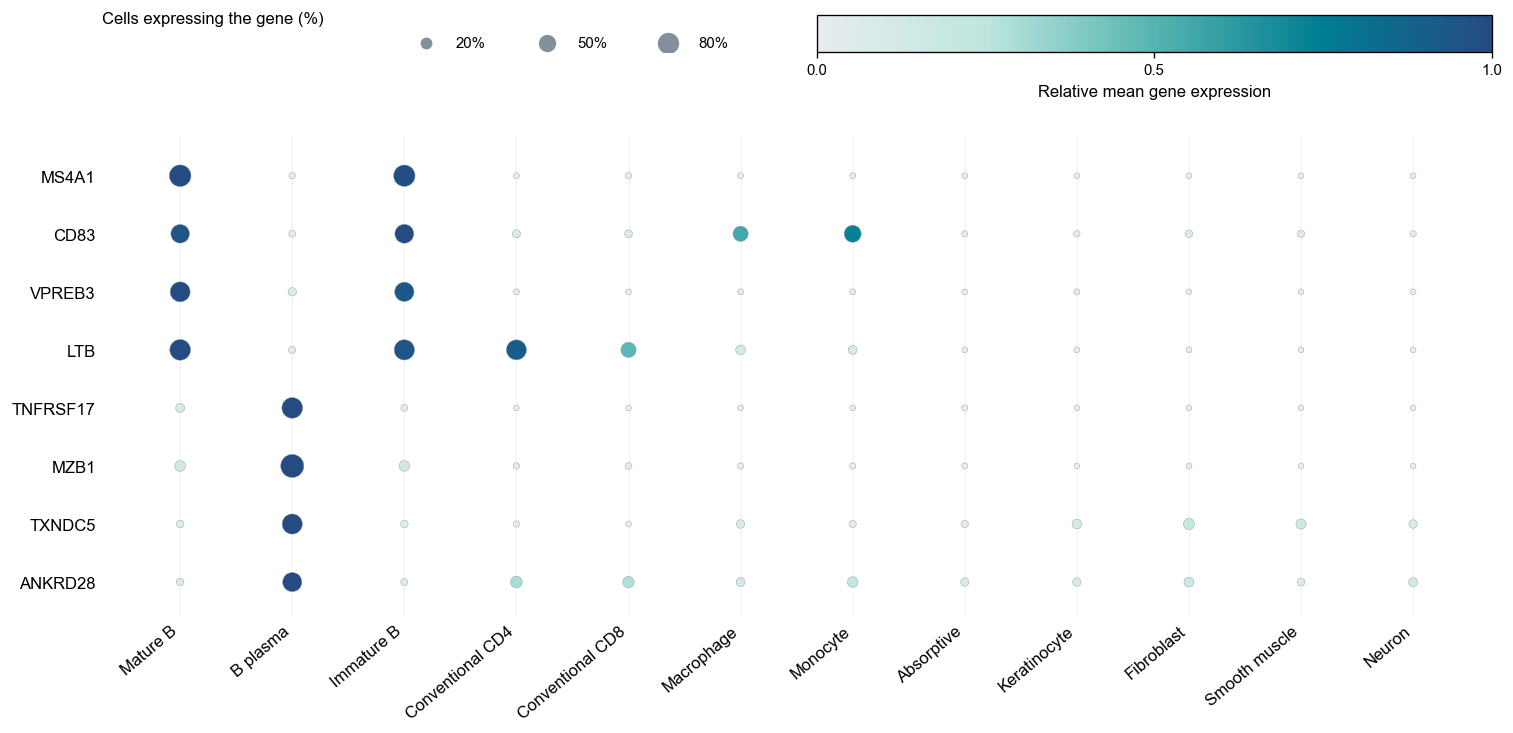

In [6]:
genes = ["MS4A1", "CD83", "VPREB3", "LTB", "TNFRSF17", "MZB1", "TXNDC5", "ANKRD28"]
populations = ["Mature_B", "B_plasma", "Immature_B", "Conventional_CD4", "Conventional_CD8",
               "Macrophage", "Monocyte", "Absorptive", "Keratinocyte", "Fibroblast", "Smooth_muscle", "Neuron"]
means = cells.groupby("cell_type")[genes].mean()
fraction = cells[genes].gt(0).groupby(cells.cell_type).mean()
values = (means / means.max().clip(lower=1e-8)).loc[populations].T
fraction = fraction.loc[populations].T
fig, ax = dot_atlas(values, fraction, "Relative mean gene expression", "Cells expressing the gene (%)")
save_figure(fig, OUTPUT, "pangi_marker_expression_dotplot")
plt.show()